# 02 · Exploratory data analysis

Notebook 01 established that the data is clean and that 14 sensors are worth keeping. This notebook looks at **how engines degrade**. The questions are:

1. How much do engine lifetimes vary, and how do test engines differ from training engines?
2. Is there more than one operating regime that needs separate normalisation?
3. How do the sensors behave as an engine approaches failure, and which are the most informative?
4. What do the answers imply for the **target** (linear vs. capped RUL) and for the **features** built in notebook 03?

In [1]:
import sys
from pathlib import Path

REPO = "https://github.com/WhiteHacker000/Remaining-Useful-Life-Prediction-for-Industrial-Engines.git"

# On Google Colab only the notebook is opened, so clone the repository to get src/ and the data
if "google.colab" in sys.modules and not Path("../src").exists():
    import os, subprocess
    if not Path("/content/rul").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/rul"], check=True)
    os.chdir("/content/rul/notebooks")

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

from src.config import SENSOR_INFO, USEFUL_SENSORS, SETTING_COLS, RUL_CAP
from src.data import load_cmapss, add_train_rul, add_test_rul
from src.plotting import set_style, save, BLUE, ORANGE, AQUA, GREY, INK, DIVERGING

set_style()

train, test, rul = load_cmapss("FD001")
train, test = add_train_rul(train), add_test_rul(test, rul)
label = lambda s: f"{s} · {SENSOR_INFO[s][0]}"

## 1. Engine lifetimes

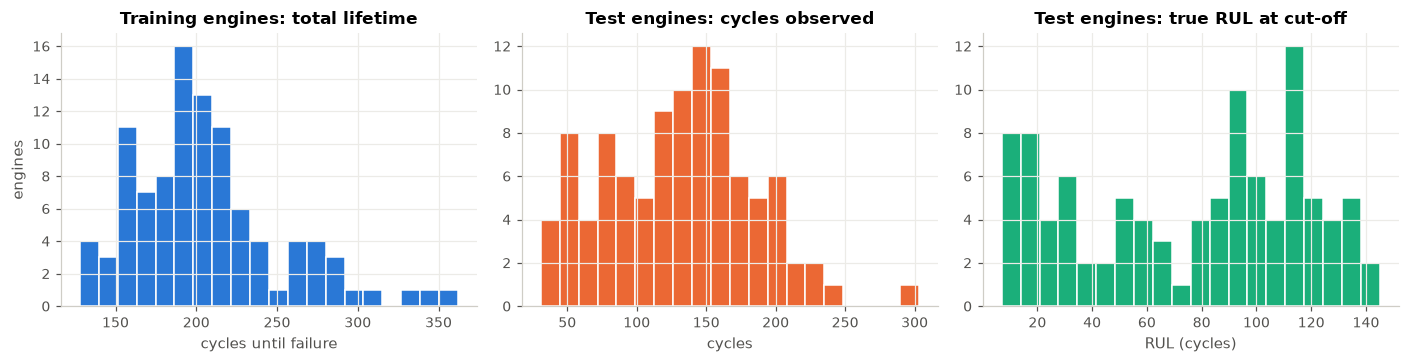

,count,mean,std,min,25%,50%,75%,max
train lifetime,100.0,206.3,46.3,128.0,177.0,199.0,229.2,362.0
test observed,100.0,131.0,53.6,31.0,88.8,133.5,164.2,303.0
test true RUL,100.0,75.5,41.8,7.0,32.8,86.0,112.2,145.0


In [2]:
lifetimes = train.groupby("unit")["cycle"].max()
observed = test.groupby("unit")["cycle"].max()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(lifetimes, bins=20, color=BLUE, edgecolor="white")
axes[0].set(title="Training engines: total lifetime", xlabel="cycles until failure", ylabel="engines")
axes[1].hist(observed, bins=20, color=ORANGE, edgecolor="white")
axes[1].set(title="Test engines: cycles observed", xlabel="cycles")
axes[2].hist(rul, bins=20, color=AQUA, edgecolor="white")
axes[2].set(title="Test engines: true RUL at cut-off", xlabel="RUL (cycles)")
fig.tight_layout()
save(fig, "02_lifetimes")
plt.show()

pd.DataFrame({"train lifetime": lifetimes.describe(), "test observed": observed.describe(),
              "test true RUL": rul.describe()}).T.round(1)

- Training lifetimes are right-skewed: most engines fail between 160 and 230 cycles, but a few last over 300. The spread (std about 46 cycles) is large, so cycle count alone is a weak predictor.
- Test engines are observed for 131 cycles on average, against a mean lifetime of 206 for training engines. They are earlier in their lives, which is the realistic prognostics setting.
- True test RUL ranges from 7 to 145 cycles. We only look at its distribution here; the test labels are not used for any modelling decision.

## 2. Operating conditions

The project brief asks to *normalise sensors by training operating regime*. Sensor readings depend strongly on altitude, Mach number and throttle (the three settings). If engines ran under several conditions, a "high" temperature could mean degradation or just a different flight condition. We plot the settings for FD001 and, for comparison, FD002.

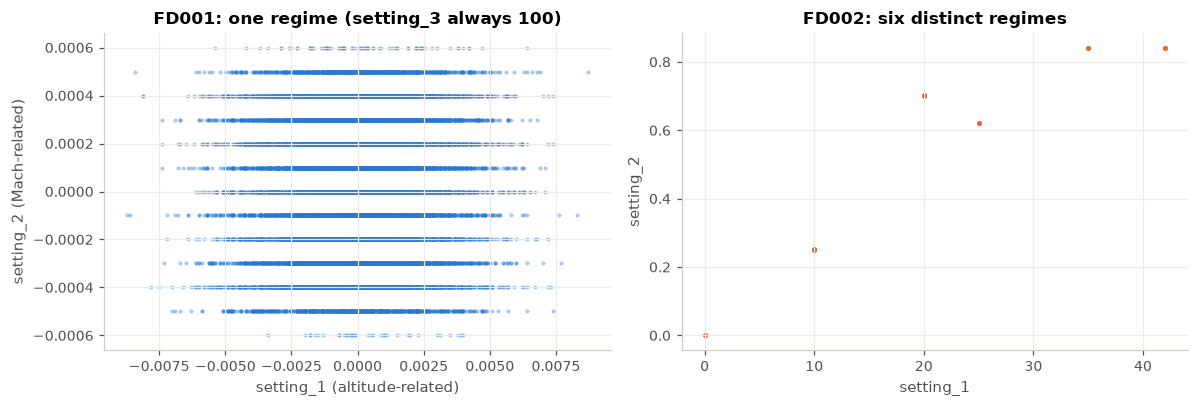

FD001 distinct (rounded) setting combinations: 1
FD002 distinct (rounded) setting combinations: 6


In [3]:
train_fd002, _, _ = load_cmapss("FD002")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(train["setting_1"], train["setting_2"], s=3, alpha=0.3, color=BLUE)
axes[0].set(title=f"FD001: one regime (setting_3 always {train['setting_3'].iloc[0]:.0f})",
            xlabel="setting_1 (altitude-related)", ylabel="setting_2 (Mach-related)")
axes[1].scatter(train_fd002["setting_1"], train_fd002["setting_2"], s=3, alpha=0.3, color=ORANGE)
axes[1].set(title="FD002: six distinct regimes", xlabel="setting_1", ylabel="setting_2")
fig.tight_layout()
save(fig, "02_operating_conditions")
plt.show()

print("FD001 distinct (rounded) setting combinations:",
      train[SETTING_COLS].round(0).drop_duplicates().shape[0])
print("FD002 distinct (rounded) setting combinations:",
      train_fd002[SETTING_COLS].round(0).drop_duplicates().shape[0])

In FD001 the settings form one tight cloud around zero: a **single operating regime**, so normalising per regime is the same as a global z-score. FD002 has six well-separated clusters, and there the per-regime step is essential.

We still implement regime clustering and per-regime normalisation in `src/features.py` (`RegimeScaler`). It is applied to FD001 with one regime, and notebook 03 shows it working on FD002, so the pipeline extends to the harder subsets.

## 3. How sensors change as an engine approaches failure

To compare engines with different lifetimes, we **align them at failure**: the x-axis is cycles *before* failure (−RUL), so every engine ends at 0. Grey lines are individual engines; the blue line is the median across engines.

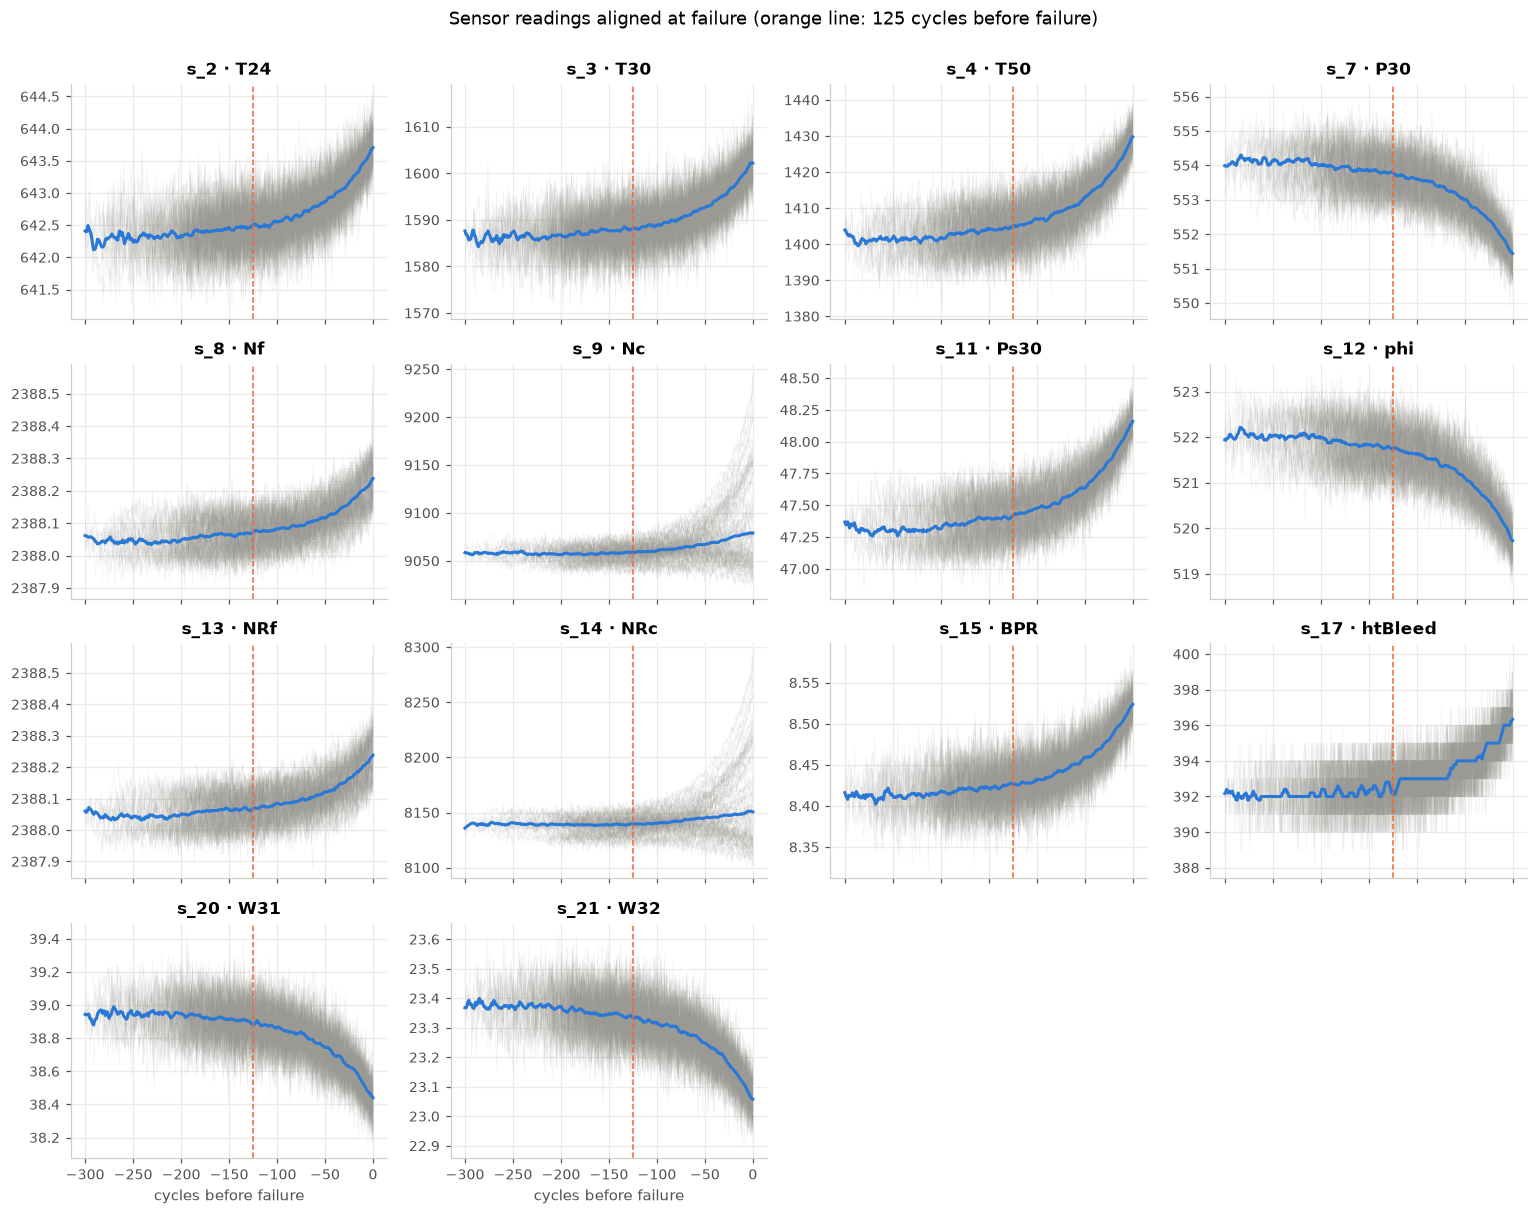

In [4]:
aligned = train[train["RUL"] <= 300]
median = aligned.groupby("RUL")[USEFUL_SENSORS].median()

fig, axes = plt.subplots(4, 4, figsize=(14, 11), sharex=True)
for ax, s in zip(axes.flat, USEFUL_SENSORS):
    for _, e in aligned.groupby("unit"):
        ax.plot(-e["RUL"], e[s], color=GREY, lw=0.5, alpha=0.12)
    ax.plot(-median.index, median[s].rolling(5, center=True, min_periods=1).mean(), color=BLUE, lw=2)
    ax.axvline(-RUL_CAP, color=ORANGE, ls="--", lw=1)
    ax.set_title(label(s))
for ax in axes.flat[len(USEFUL_SENSORS):]:
    ax.axis("off")
for ax in axes[-1]:
    ax.set_xlabel("cycles before failure")
fig.suptitle(f"Sensor readings aligned at failure (orange line: {RUL_CAP} cycles before failure)", y=1.0, fontsize=12)
fig.tight_layout()
save(fig, "02_sensor_trajectories")
plt.show()

Three patterns stand out:

- **Flat, then a trend.** Most sensors hover around a constant level for a long time and only start to drift in the last 100 to 150 cycles. Temperatures (`s_2`, `s_3`, `s_4`), static pressure `s_11` and bypass ratio `s_15` rise; HPC outlet pressure `s_7`, fuel-flow ratio `s_12` and the coolant bleeds `s_20`, `s_21` fall. This is what a growing HPC fault looks like.
- **Core speed behaves differently.** For `s_9` (Nc) and `s_14` (NRc) the median barely moves: a minority of engines shoot up near the end while others stay flat or drift down. This engine-to-engine variation is exactly what fixed features may struggle with.
- **Noise is large.** At any point in life the readings of different engines (and successive readings of one engine) scatter widely, so a single reading says little. Features need to smooth over several cycles (section 6).

## 4. Ranking sensors by prognostic quality

Correlation with RUL is one way to rank sensors, but prognostics has dedicated criteria (Coble & Hines, 2009). We compute three of them on smoothed signals (20-cycle rolling mean), each between 0 and 1, higher is better:

- **Monotonicity**: does the signal keep moving in one direction? $\;M = \frac{1}{N}\sum_i \frac{|\#\{\Delta x>0\} - \#\{\Delta x<0\}|}{n_i - 1}$
- **Trendability**: does it track engine age? We use the mean absolute Spearman correlation between the signal and the cycle index, per engine.
- **Prognosability**: do engines end at a similar value? $\;P = \exp\left(-\frac{\text{std}(x_{\text{fail}})}{\text{mean}|x_{\text{fail}} - x_{\text{start}}|}\right)$, using the means of the first and last 10 cycles.

`s_6` is included as a reference for a sensor we dropped.

In [5]:
def prognostic_metrics(df, sensors, smooth=20):
    rows = {}
    for s in sensors:
        mono, trend, start, end = [], [], [], []
        for _, e in df.groupby("unit"):
            x = e[s].rolling(smooth, min_periods=1).mean().to_numpy()
            d = np.sign(np.diff(x))
            mono.append(abs(d.sum()) / len(d))
            rho = spearmanr(x, np.arange(len(x)))[0]
            trend.append(0.0 if np.isnan(rho) else abs(rho))
            start.append(e[s].iloc[:10].mean())
            end.append(e[s].iloc[-10:].mean())
        start, end = np.array(start), np.array(end)
        change = np.abs(end - start).mean()
        prog = np.exp(-end.std() / change) if change > 0 else 0.0
        rows[s] = {"monotonicity": np.mean(mono), "trendability": np.mean(trend), "prognosability": prog}
    out = pd.DataFrame(rows).T
    out["average"] = out.mean(axis=1)
    return out.sort_values("average", ascending=False)

metrics = prognostic_metrics(train, USEFUL_SENSORS + ["s_6"])
metrics.round(3)

,monotonicity,trendability,prognosability,average
s_11,0.309,0.953,0.936,0.733
s_4,0.277,0.943,0.944,0.721
s_12,0.288,0.942,0.879,0.703
s_7,0.262,0.926,0.894,0.694
s_15,0.227,0.915,0.935,0.692
s_21,0.218,0.924,0.928,0.690
s_20,0.217,0.924,0.925,0.689
s_2,0.192,0.902,0.925,0.673
s_17,0.182,0.896,0.895,0.658
s_3,0.174,0.888,0.887,0.650


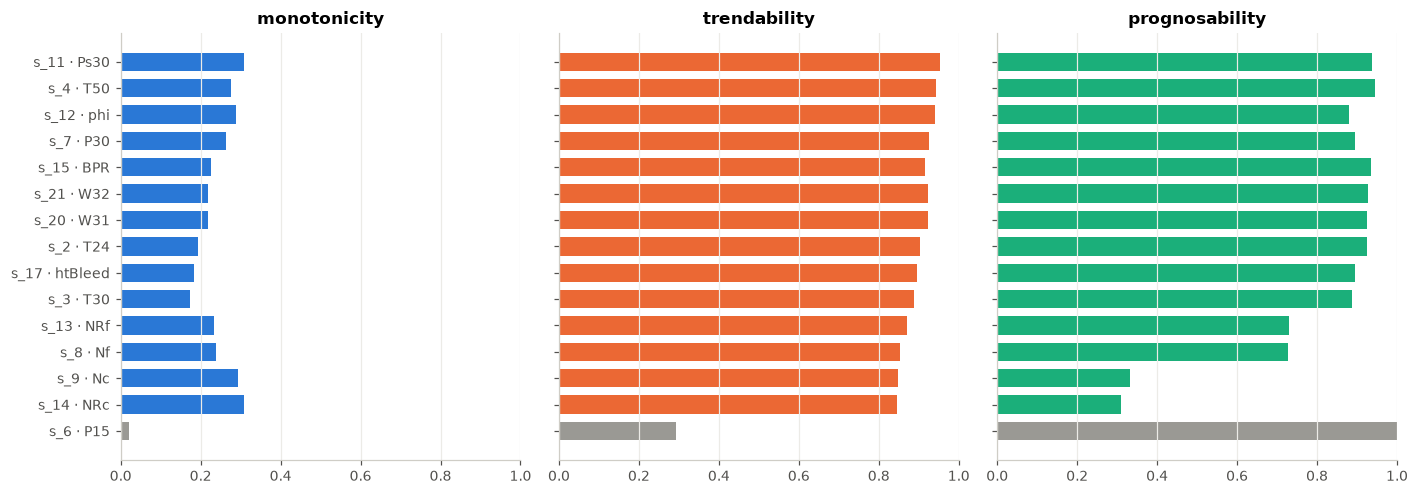

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
order = metrics.index[::-1]
for ax, col, color in zip(axes, ["monotonicity", "trendability", "prognosability"], [BLUE, ORANGE, AQUA]):
    colors = [GREY if s == "s_6" else color for s in order]
    ax.barh([label(s) for s in order], metrics.loc[order, col], color=colors, height=0.7)
    ax.set(title=col, xlim=(0, 1))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "02_prognostic_metrics")
plt.show()

The ranking agrees with the trajectory plots:

- `s_11`, `s_4`, `s_12`, `s_7`, `s_15`, `s_21`, `s_20` and `s_17` score well on all three criteria: they trend steadily and end at similar values.
- `s_9` and `s_14` (core speeds) have the lowest prognosability of the kept sensors: they degrade, but engines end at very different values.
- `s_6` (grey) is clearly worst on monotonicity and trendability (close to 0), which confirms dropping it. Its prognosability of 1.0 is an artefact: the measure divides by the change over life, and a sensor that hardly changes makes it meaningless.
- Monotonicity is low for every sensor (at most about 0.3) because even a 20-cycle mean still wiggles up and down. Trendability and prognosability separate the sensors more clearly.

We keep all 14 sensors as model inputs. The tree models and the L1 part of Elastic Net can down-weight weaker sensors on their own, and notebook 05 checks which ones the models end up using.

## 5. Correlation between sensors

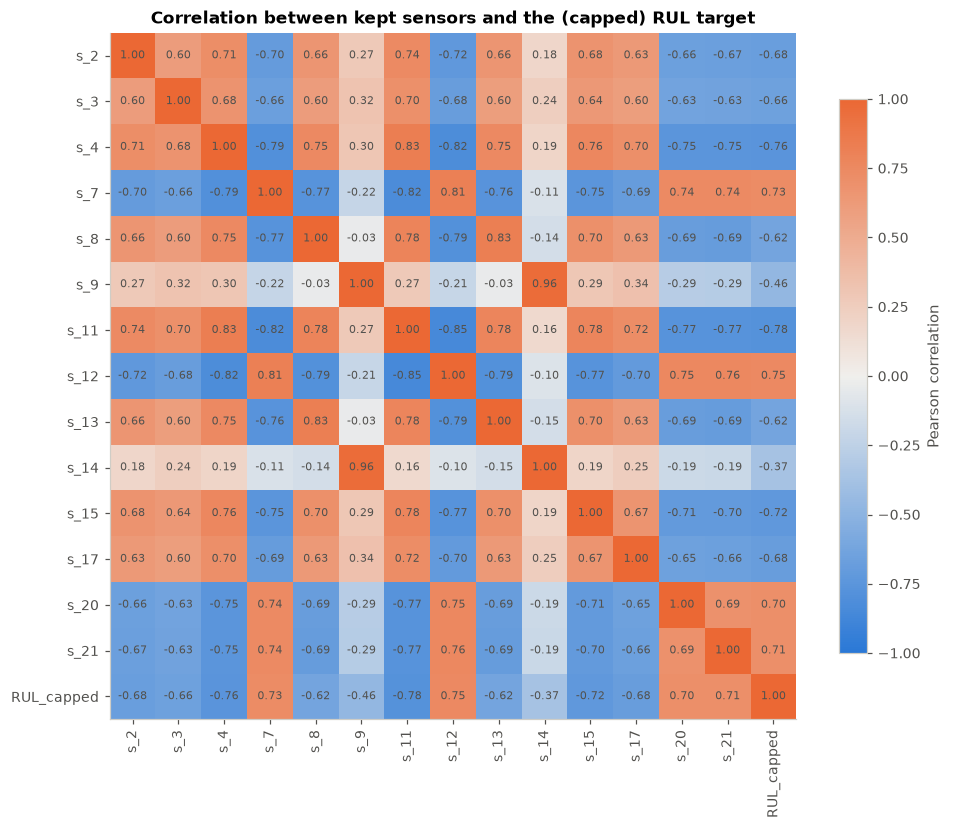

,RUL_capped
s_11,-0.775
s_4,-0.757
s_12,0.749
s_7,0.733
s_15,-0.721
s_21,0.707
s_20,0.705
s_17,-0.681
s_2,-0.678
s_3,-0.655


In [7]:
corr = train[USEFUL_SENSORS].assign(RUL_capped=train["RUL"].clip(upper=RUL_CAP)).corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between kept sensors and the (capped) RUL target")
fig.tight_layout()
save(fig, "02_correlation")
plt.show()

corr["RUL_capped"].drop("RUL_capped").sort_values(key=abs, ascending=False).round(3).to_frame()

- Most sensors are strongly correlated with each other (|r| often above 0.7), because they all respond to the same underlying fault. `s_9` and `s_14` are almost duplicates (r ≈ 0.96).
- Correlation with the capped RUL reaches about 0.8 for `s_11`, `s_4`, `s_12` and `s_7`, but no single sensor explains RUL on its own.
- **Implication for modelling:** strong multicollinearity makes plain linear regression coefficients unstable. This is the reason for **Elastic Net**: its L2 part spreads weight across correlated sensors and its L1 part can drop redundant ones. Tree models are not affected by collinearity in their predictions.

## 6. Noise versus trend

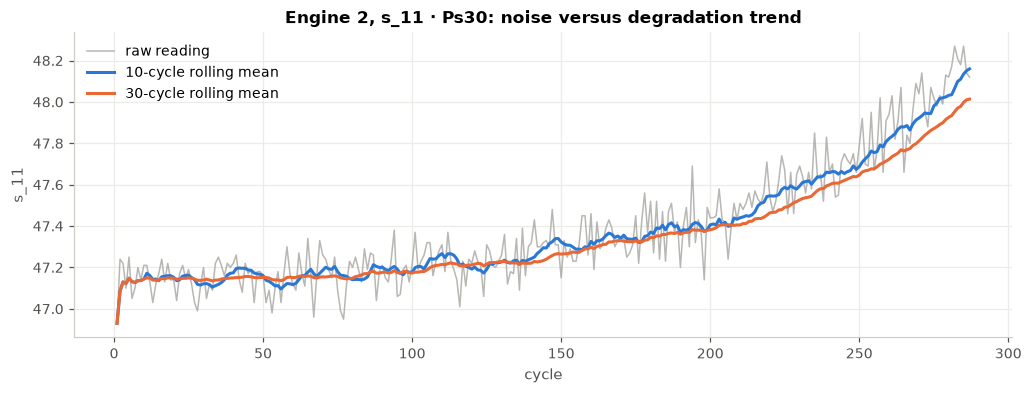

cycle-to-cycle noise (std): 0.096   total change over life: 1.016


In [8]:
e = train[train["unit"] == 2]
s = "s_11"
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(e["cycle"], e[s], color=GREY, lw=1, alpha=0.7, label="raw reading")
ax.plot(e["cycle"], e[s].rolling(10, min_periods=1).mean(), color=BLUE, label="10-cycle rolling mean")
ax.plot(e["cycle"], e[s].rolling(30, min_periods=1).mean(), color=ORANGE, label="30-cycle rolling mean")
ax.set(title=f"Engine 2, {label(s)}: noise versus degradation trend", xlabel="cycle", ylabel=s)
ax.legend()
save(fig, "02_noise_smoothing")
plt.show()

noise = e[s].diff().std() / np.sqrt(2)
trend = e[s].iloc[-10:].mean() - e[s].iloc[:10].mean()
print(f"cycle-to-cycle noise (std): {noise:.3f}   total change over life: {trend:.3f}")

The noise on a single reading (std about 0.10 psia) is about a tenth of the total change over the whole life (about 1.0 psia). Over any 10 to 20 cycle stretch, the change due to degradation is smaller than the noise, so two consecutive readings cannot show the trend. A 10-cycle mean shows it much more clearly, and a 30-cycle window is smoother still but reacts later. This motivates the **rolling mean**, **rolling standard deviation** and **rolling slope** features at two window lengths in notebook 03.

## 7. Train versus test distributions

Test engines are cut off before failure, so their readings should look "healthier" on average. We check that the test data comes from the same range as the training data and that nothing else differs.

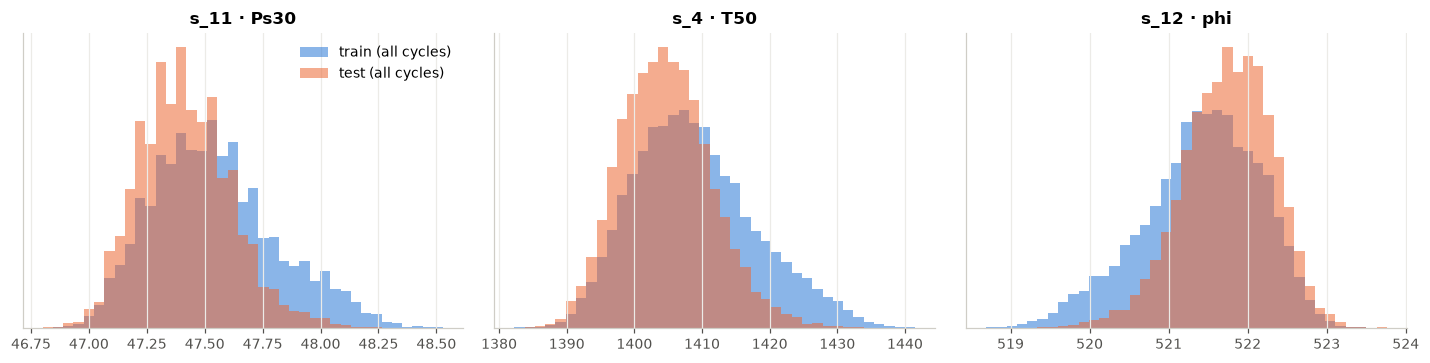

,train mean,test mean,shift (in train std)
s_11,47.541,47.416,-0.468
s_4,1408.934,1404.735,-0.466
s_12,521.413,521.748,0.453
s_7,553.368,553.758,0.440
s_15,8.442,8.426,-0.435
s_21,23.290,23.336,0.425


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, s in zip(axes, ["s_11", "s_4", "s_12"]):
    bins = np.linspace(min(train[s].min(), test[s].min()), max(train[s].max(), test[s].max()), 40)
    ax.hist(train[s], bins=bins, density=True, alpha=0.55, color=BLUE, label="train (all cycles)")
    ax.hist(test[s], bins=bins, density=True, alpha=0.55, color=ORANGE, label="test (all cycles)")
    ax.set(title=label(s), yticks=[])
axes[0].legend()
fig.tight_layout()
save(fig, "02_train_vs_test")
plt.show()

shift = pd.DataFrame({"train mean": train[USEFUL_SENSORS].mean(), "test mean": test[USEFUL_SENSORS].mean()})
shift["shift (in train std)"] = (shift["test mean"] - shift["train mean"]) / train[USEFUL_SENSORS].std()
shift.round(3).sort_values("shift (in train std)", key=abs, ascending=False).head(6)

The test distributions sit inside the training range and are shifted towards the healthy end, by up to about half a training standard deviation. That is what truncation alone would produce. There is no sign of a different data source or sensor calibration, so a model trained on the training engines should transfer to the test engines.

## 8. Choosing the target: linear or piecewise-linear RUL?

The trajectory plots show that sensors are essentially **flat early in life**. An engine with 300 cycles left and one with 180 left look the same. Asking a model to tell them apart (a *linear* RUL target) means asking it to predict something the sensors do not contain, which adds noise to training.

The common fix, introduced by Heimes (2008) and used in most C-MAPSS studies, is a **piecewise-linear target**: RUL is held constant at a cap $R_{max}$ during healthy operation and decreases linearly afterwards:

$$y_{i,t} = \min(\text{RUL}_{i,t},\; R_{max})$$

To check where degradation becomes visible, we combine the 14 sensors into one indicator: z-score each sensor, flip its sign so it increases towards failure, and average.

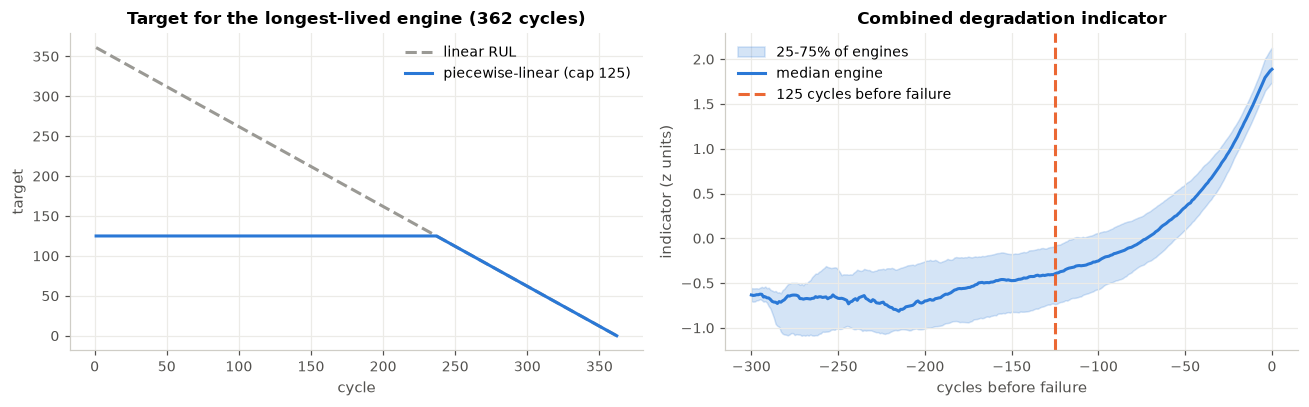

median indicator has risen   5% of the way to its failure value at about 180 cycles before failure
median indicator has risen  10% of the way to its failure value at about 140 cycles before failure
median indicator has risen  25% of the way to its failure value at about 76 cycles before failure


In [10]:
z = (train[USEFUL_SENSORS] - train[USEFUL_SENSORS].mean()) / train[USEFUL_SENSORS].std()
direction = np.sign(z.corrwith(-train["RUL"]))
train["indicator"] = (z * direction).mean(axis=1)

band = train[train["RUL"] <= 300].groupby("RUL")["indicator"].quantile([0.25, 0.5, 0.75]).unstack()
band = band.rolling(9, center=True, min_periods=1).mean()
early_level = band.loc[200:300, 0.5].mean()
rise = band.loc[0, 0.5] - early_level
onset = {p: band.index[band[0.5] > early_level + p * rise].max() for p in [0.05, 0.10, 0.25]}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
e = train[train["unit"] == lifetimes.idxmax()]
axes[0].plot(e["cycle"], e["RUL"], color=GREY, ls="--", label="linear RUL")
axes[0].plot(e["cycle"], e["RUL"].clip(upper=RUL_CAP), color=BLUE, label=f"piecewise-linear (cap {RUL_CAP})")
axes[0].set(title=f"Target for the longest-lived engine ({lifetimes.max()} cycles)", xlabel="cycle", ylabel="target")
axes[0].legend()

axes[1].fill_between(-band.index, band[0.25], band[0.75], color=BLUE, alpha=0.2, label="25-75% of engines")
axes[1].plot(-band.index, band[0.5], color=BLUE, label="median engine")
axes[1].axvline(-RUL_CAP, color=ORANGE, ls="--", label=f"{RUL_CAP} cycles before failure")
axes[1].set(title="Combined degradation indicator", xlabel="cycles before failure", ylabel="indicator (z units)")
axes[1].legend(loc="upper left")
fig.tight_layout()
save(fig, "02_target_choice")
plt.show()

for p, c in onset.items():
    print(f"median indicator has risen {p:>4.0%} of the way to its failure value at about {c} cycles before failure")

The median indicator is flat (and noisy) until about 200 cycles before failure, creeps up slowly, and then accelerates over the last 125 or so cycles. It reaches 10% of its total rise at about 140 cycles before failure. Before that, the spread between engines (the shaded band) is much larger than the change in the median, so the sensors carry very little information about how much life is left. A cap somewhere between about 120 and 150 matches the data.

We therefore use a **piecewise-linear target with $R_{max}$ = 125** as the working choice. It also matches the value used by most published C-MAPSS work, which makes our results easier to compare. Since the brief says to cap the target only if justified, notebook 04 tests it directly: a linear target against several cap values, under the same cross-validation.

## Summary of findings and what they mean for the next steps

| Finding | Consequence |
|---|---|
| Lifetimes range from 128 to 362 cycles | cycle count alone is weak; engine-specific degradation must be read from sensors |
| FD001 has a single operating regime | per-regime normalisation = z-score here; implemented generally for FD002/FD004 |
| Sensors are flat early, then trend over the last ~125-150 cycles | piecewise-linear target with cap 125 (tested in notebook 04) |
| Readings are noisy relative to the trend | rolling mean / std / slope features over 10 and 30 cycles |
| Engines start at different health levels | features relative to each engine's own early-life baseline |
| Sensors are highly collinear | Elastic Net instead of plain linear regression; a combined health index |
| `s_9`/`s_14` degrade differently across engines | a known weak spot for fixed-window features; revisited in notebook 05 |